In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append(r"D:\Python\import\nimm-main")

In [3]:
import nimm

# 测试插件baseplugin类

**<font face="黑体" color=blue size = 5>BasePlugin()</font>** 类，使用函数调用时，默认调用类中process()函数  
可以继承该类，创建自己的功能类

In [4]:
from nimm import BasePlugin

In [5]:
class sample_c(BasePlugin):
    def __init__(self,
                str1='hello',
                str2='world',
                ):
        self.str1 = str1
        self.str2 = str2
    
    def process(self, str3='!'):
        str_t = self.str1+self.str2+str3
        print(str_t)

In [6]:
a = sample_c()
a(str3='nonono')

helloworldnonono


# 基础cube数据测试

## 单变量CUBE网格数据构建

**<font face="黑体" color=blue size = 5>set_up_var_cube</font>**  
   ( **data: ndarray,  
    name: str = "air_temperature",  
    units: str = "K",  
    spatial_grid: str = "latlon",  
    time: datetime.datetime = datetime.datetime(2017, 11, 10, 4, 0),  
    time_bounds: Optional[Tuple[datetime.datetime, datetime.datetime]] = None,  
    frt: datetime.datetime = datetime.datetime(2017, 11, 10, 0, 0),  
    realizations: Optional[Union[List[float], ndarray]] = None,  
    include_scalar_coords: Optional[List[Coord]] = None,  
    attributes: Optional[Dict[str, str]] = None,  
    grid_spacing: Optional[float] = None,  
    domain_corner: Optional[Tuple[float, float]] = None,  
    height_levels: Optional[Union[List[float], ndarray]] = None,  
    pressure: bool = False,** 
    )  
    基础cube网格数据创建函数，根据输入的数组数据、维度信息、坐标投影信息等，生成cube数据

|参数|说明|    
|:--|:--|  
|**<font face="黑体" color=blue size = 5>data</font>**|2D (y-x ordered) or 3D (realization-y-x ordered) array of data to put into the cube. | 
|**name**| Variable name (standard / long) |  
|**<font face="黑体" color=blue size = 5>spatial_grid</font>**| What type of x/y coordinate values to use.  Permitted values are "latlon" or "equalarea". |
|**time**| Single cube forecast reference time |
|**validtime**| Single cube validity time |
|**time_bounds**| Lower and upper bound on time point, if required，eg: var = past 1h percipitation，then bounds=[-1,0] |
|**realizations**| List of forecast realizations.  If not present, taken from the leading dimension of the input data array (if 3D). |
|**include_scalar_coords**| List of iris.coords.DimCoord or AuxCoord instances of length 1. |
|**attributes**| Optional cube attributes. |
|**grid_spacing**| Grid resolution (degrees for latlon or metres for equalarea). |
|**domain_corner**| Bottom left corner of grid domain (y,x) (degrees for latlon or metres for equalarea). **equalarea projection**: LambertConformal, ***central point--(34, 105)***|
|**height_levels**| List of height levels in metres or pressure levels in Pa.|
|**pressure**| Flag to indicate whether the height levels are specified as pressure, in Pa. If False, use height in metres. |
|<font face="黑体" color=blue size=5>return</font>|**Cube containing a single variable field** | 



**调用示例**


In [12]:
from nimm.base.cube_base import set_up_var_cube

In [27]:
#  latlon CUBE initialization(等经纬度)
## data
a  =  np.random.randn(10000)
a.shape = 100,-1
a = a.astype(np.float32)
## grid_infomation
grid_spacing = 0.5# unit: °
domain_corner = (0,80)
height_levels = [0]
pressure = False
## generate cube， latlon
cube_latlon = set_up_var_cube(a,  spatial_grid='latlon',
                         grid_spacing=grid_spacing, domain_corner=domain_corner, height_levels=height_levels, pressure=pressure)
cube_latlon##

<iris 'Cube' of air_temperature / (K) (latitude: 100; longitude: 100)>

In [42]:
#  equalarea CUBE initialization(等距)
## grid_infomation
grid_spacing = 50000 #unit:m
domain_corner = (-2000000,-2000000) #默认投影中点：34°N， 105°E； domain_corne为左下角点相对投影中点的位移，unit:m
height_levels = [0]
pressure = False
## generate cube， latlon
cube_equal = set_up_var_cube(a,  spatial_grid='equalarea',
                         grid_spacing=grid_spacing, domain_corner=domain_corner, height_levels=height_levels, pressure=pressure)
cube_equal##

<iris 'Cube' of air_temperature / (K) (projection_y_coordinate: 100; projection_x_coordinate: 100)>

## CUBE数据画图测试工具

In [23]:
from nimm.base.utilities import simple_pic_iris

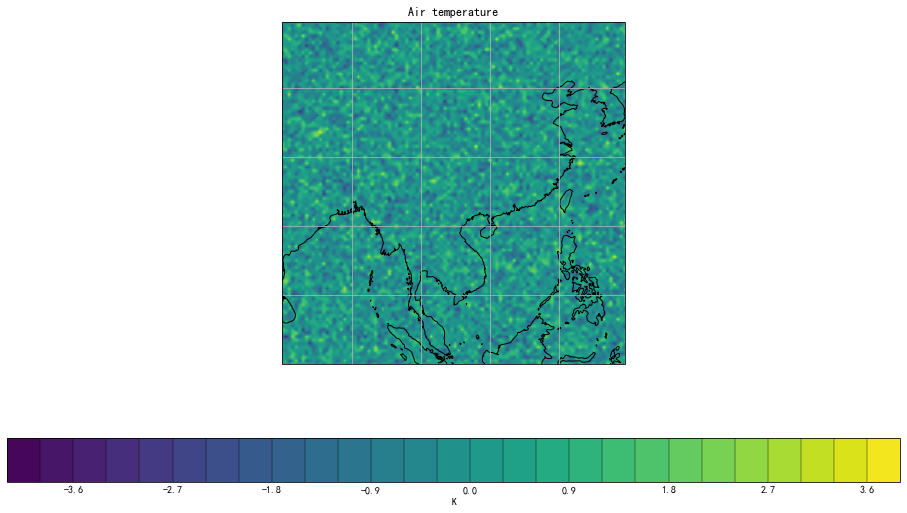

In [30]:
## 画图测试, 等经纬度网格
simple_pic_iris(cube_latlon)

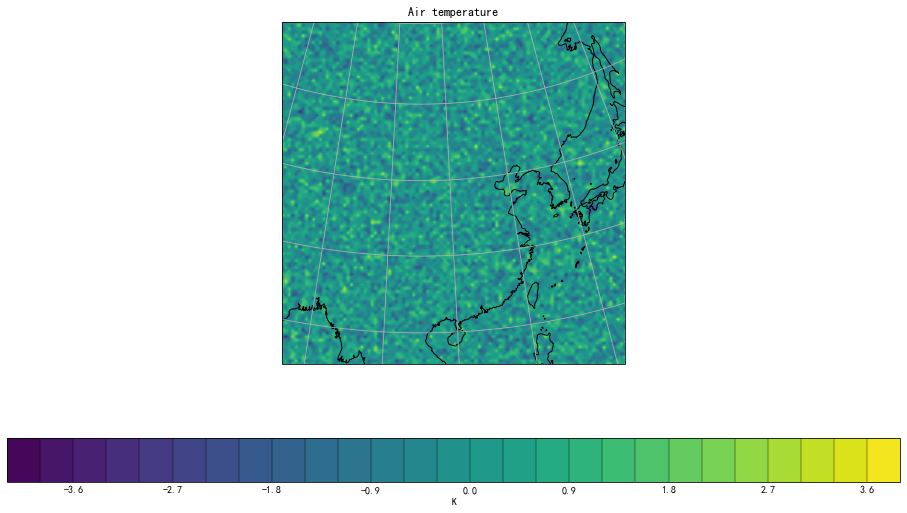

In [43]:
## 画图测试, 等距网格
simple_pic_iris(cube_equal)

# meteva_base网格数据与CUBE数据转换

meteva_base包为meteva程序库中的数据、读写、处理计算及简单绘图等工具的汇总，可以支持大部分气象数据的基础读写转换计算工作。
功能包括

- 站点、网格、线条数据在内的基础数据结构
- 多源读写(文件、GDS、天擎等)，数十种文件格式(micaps、nc、grib1/2、D131等)
- 多种数据处理转换方法(插值、选取、分组、合并、统计、诊断等)
- 以及多种实用工具(绘图、批量处理、时间处理、文件路径处理等)
- 可支持基于实况和模式预报的常规诊断、后处理及检验等工作。  


**github: https://github.com/guoyunqian/meteva_base  
install:**  *pip install meteva_base*  
**API documents: https://www.showdoc.com.cn/metevabase**  


<font face="黑体" color=blue size = 5>如果用户熟悉meteva，可使用相关API读取网格数据后，再通过下列接口转为NIMM的CUBE网格数据</font>

## 从meteva_base网格数据转为CUBE（二维网格）

**read_cube_from_meteva_griddata(xa_data, spatial_grid = 'latlon', to_grid_info=None, 
                    bounds = None ):**  
    """  
    将meteva格点(xarray)转为cube格式(标准投影插值转换流程,包括等经纬度及等距投影)  
    Args:  
        xa_data (xarray.da):   
            Meteva_base griddata (xarray data read by meteva_base python lib). 
        spatial_grid: 'latlon' # 转换为等经纬度投影('latlon')或等距网格（'equalarea'）,默认为latlon  
        to_grid_info: 转换到数据的网格信息，有两种模式构建：  
                01. meteva_base.grid网格信息类(https://www.showdoc.com.cn/metevabase/10266280656401547)  
                同时完成插值和转换，只支持转为等经纬度CUBE  
                02. 转换至CUBE网格信息字典grid_dict  
                持转换为等经纬度与等距两种投影形式CUBE。模板如下  
                grid_dict = { 'dlon':10000, 'dlat':10000, #数据xy间隔(等经纬度单位°，等距单位m)  
                'slon':70, 'slat':0, #起始点经纬度(ccrs.PlateCarree()中对应起始点坐标)  
                'nlon':701,'nlat':601 #x/y方向格点数  
                } 
        bounds: 预报要素的time point范围，如var = past 1h percipitation，则bounds=[-1,0]  
    Return:  
        cube: Iris.Cube, 等经纬度或等距投影的CUBE网格数据  
    """  

In [13]:
from nimm.base.cube_base import read_cube_from_meteva_griddata

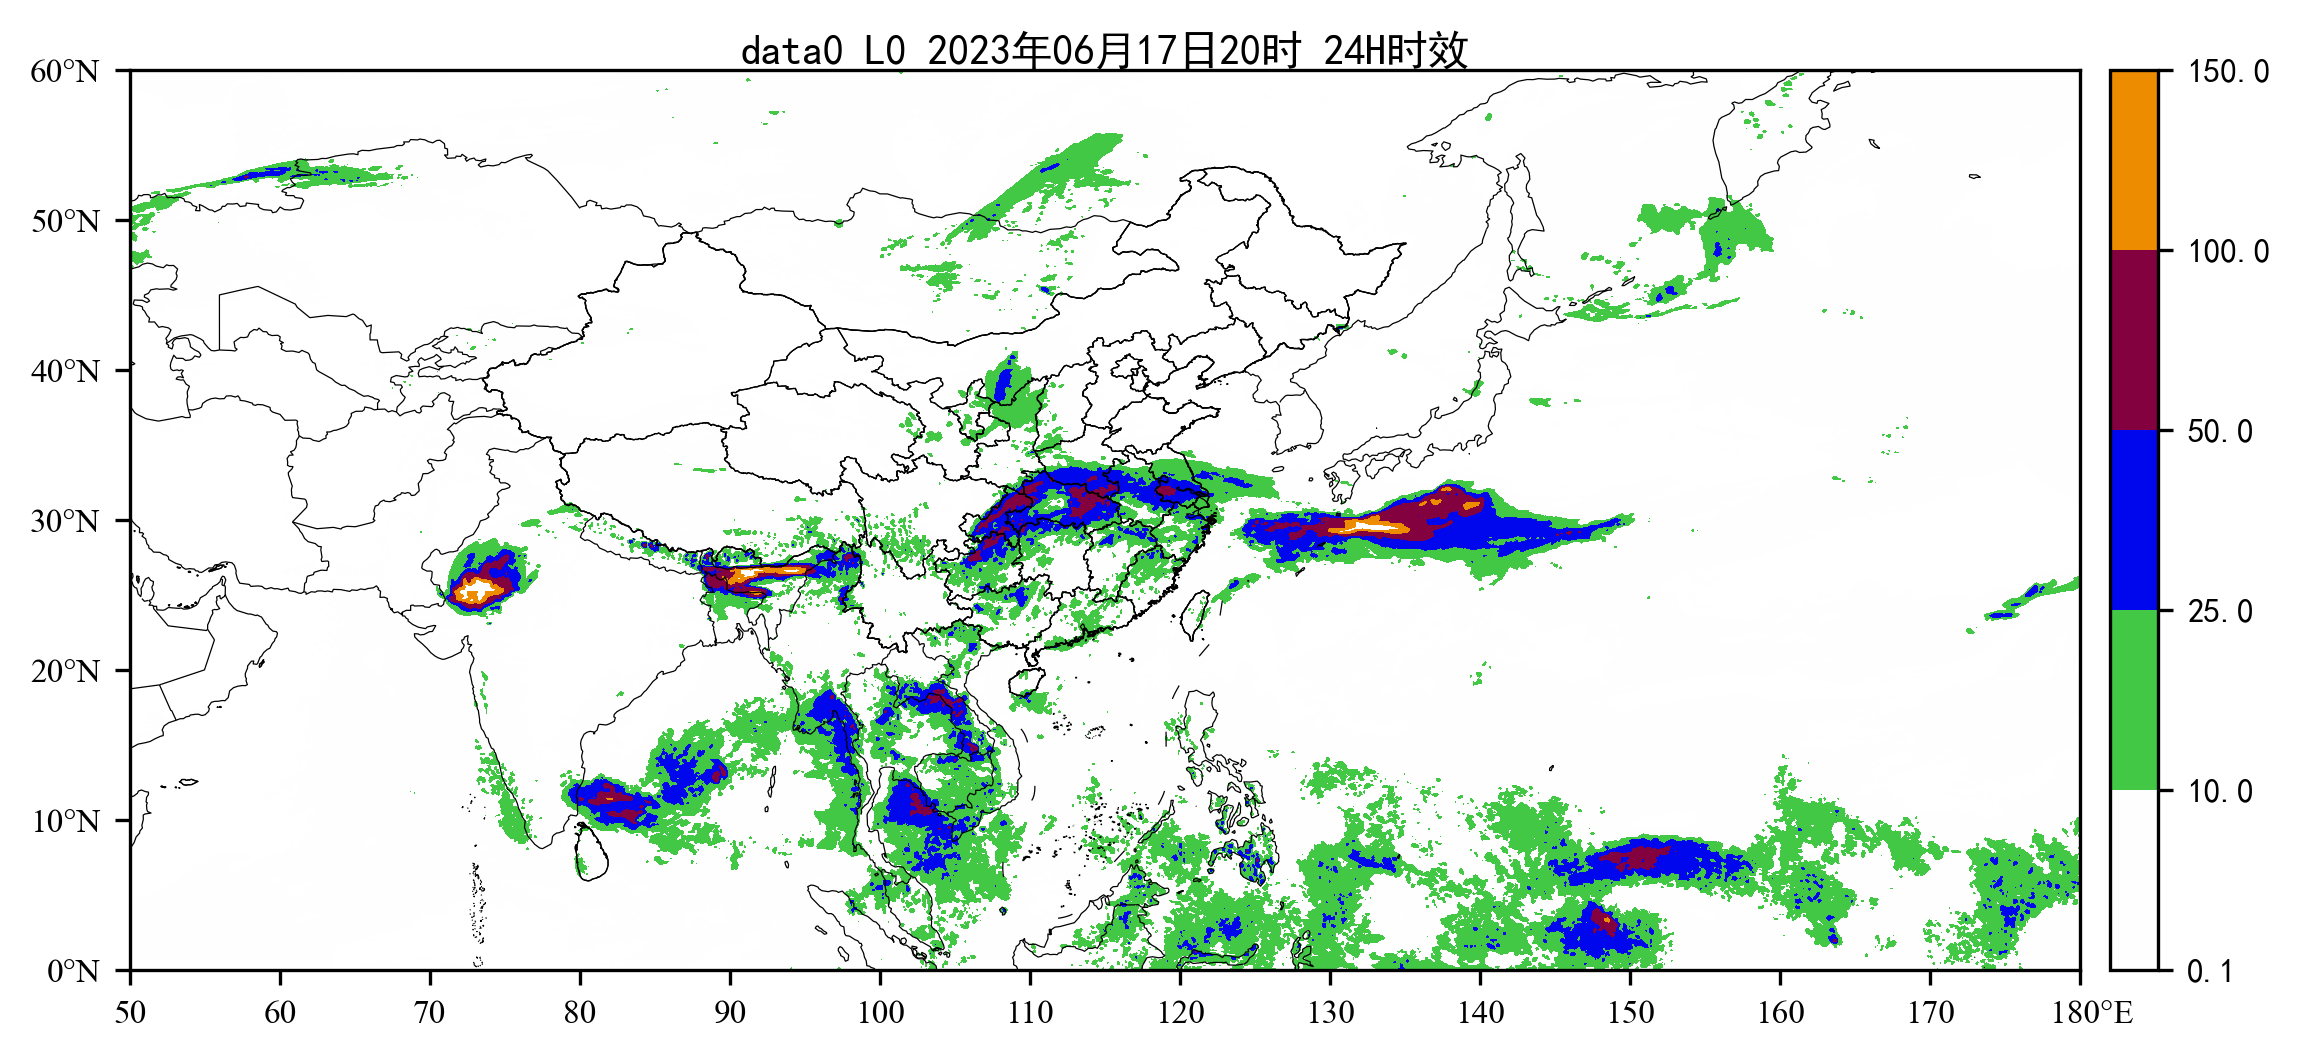

In [14]:
import meteva_base as meb
file = r"\\10.20.90.107\sm_model\rain24\ecmwf\20230617\2023061712.024"#QPE
grd = meb.read_griddata_from_micaps4(file)
meb.tool.plot_tools.contourf_2d_grid(grd,clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)

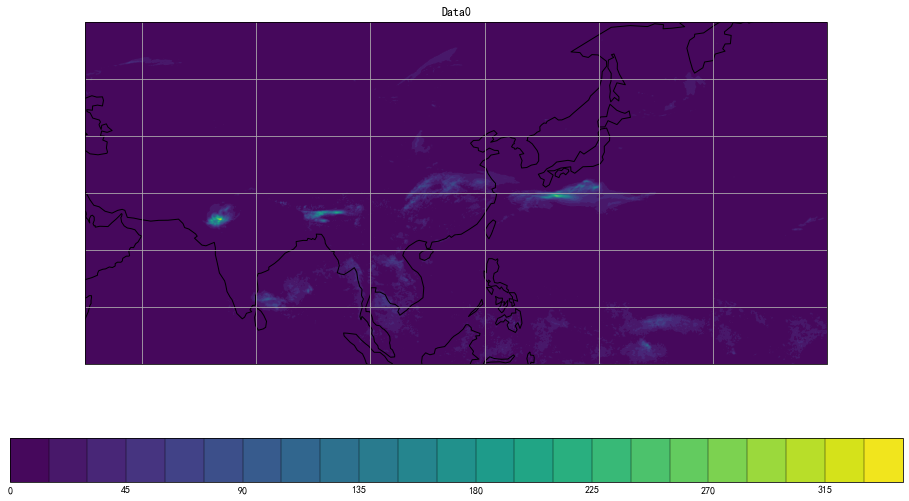

In [15]:
## 转为默认等经纬度cube
cube0 = read_cube_from_meteva_griddata(grd)
simple_pic_iris(cube0)

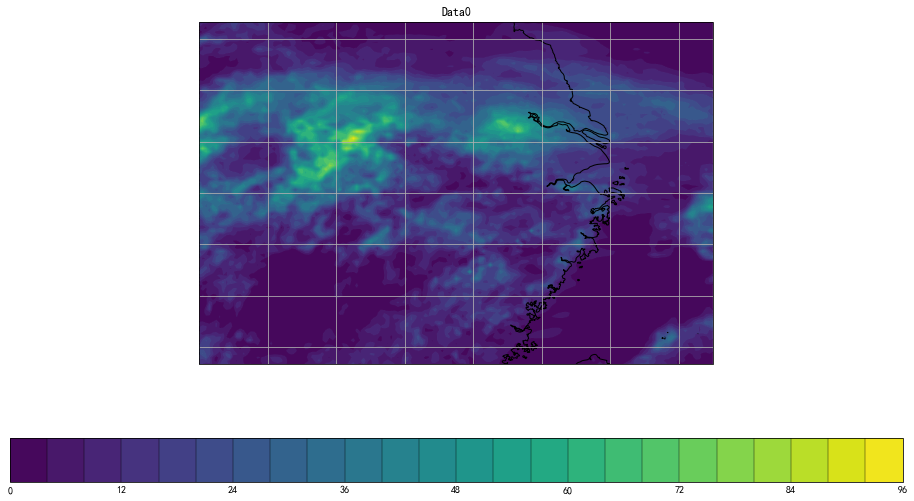

data0 / (unknown)                   (latitude: 101; longitude: 151)
     Dimension coordinates:
          latitude                           x               -
          longitude                          -               x
     Scalar coordinates:
          forecast_period: 86400 seconds
          forecast_reference_time: 2023-06-17 20:00:00
          time: 2023-06-18 20:00:00


In [16]:
## 根据meb.grid类网格信息， 转换为等经纬度cube
to_grid_info = meb.grid([110,125,0.1],[25,35,0.1])
cube1 = read_cube_from_meteva_griddata(grd, to_grid_info=to_grid_info)#网格信息为 meb.grib类
simple_pic_iris(cube1)
print(cube1)

members:['data0']
levels:[2]
gtime:['20220201000000', '20220201000000', '1h']
dtimes:[24]
glon:[110, 125.0, 0.03]
glat:[25, 34.0, 0.03]



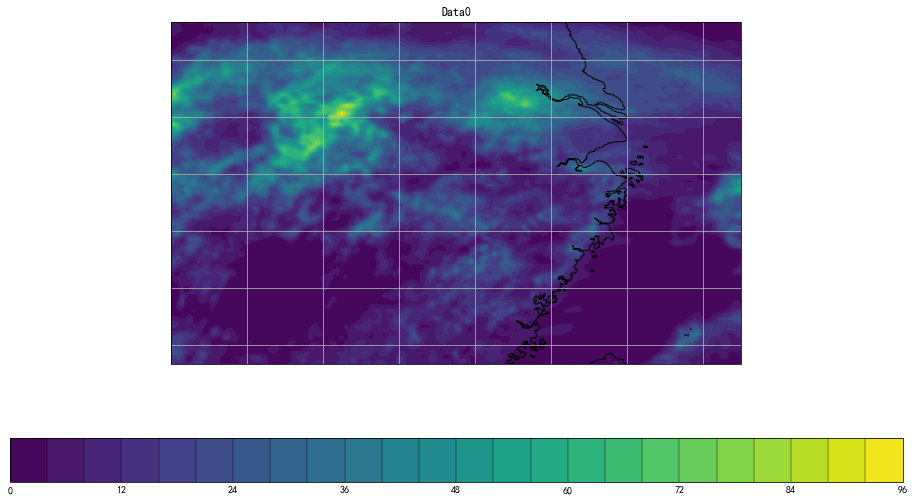

data0 / (unknown)                   (latitude: 301; longitude: 501)
     Dimension coordinates:
          latitude                           x               -
          longitude                          -               x
     Scalar coordinates:
          forecast_period: 86400 seconds
          forecast_reference_time: 2023-06-17 20:00:00
          time: 2023-06-18 20:00:00


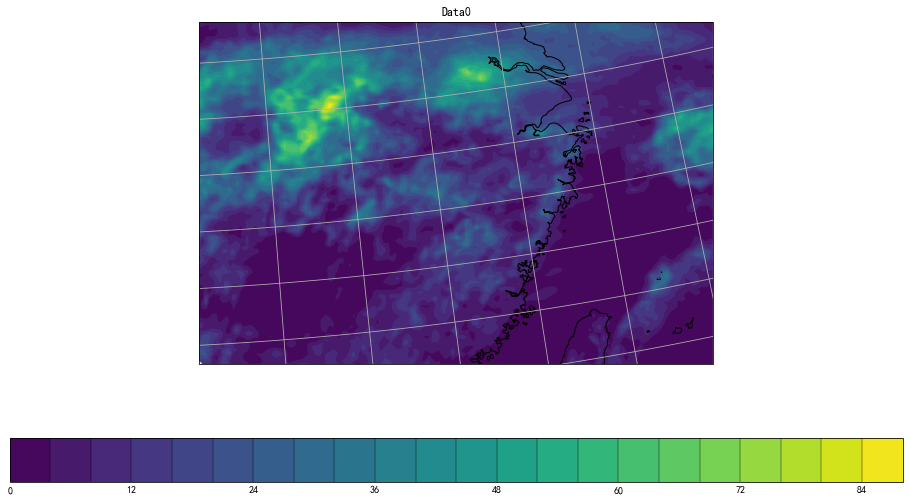

data0 / (unknown)                   (projection_y_coordinate: 101; projection_x_coordinate: 151)
     Dimension coordinates:
          projection_y_coordinate                           x                             -
          projection_x_coordinate                           -                             x
     Scalar coordinates:
          forecast_period: 86400 seconds
          forecast_reference_time: 2023-06-17 20:00:00
          time: 2023-06-18 20:00:00


In [29]:
## 根据网格信息字典， 转换为等经纬度或等距cube
to_grid_dict  = { 'dlon':0.03, 'dlat':0.03, #数据xy间隔
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':501,'nlat':301,
                }#等经纬度网格，距离单位°
spatial_grid = 'latlon'
cube2 = read_cube_from_meteva_griddata(grd, spatial_grid=spatial_grid, to_grid_info=to_grid_dict)#网格信息为 meb.grib类
simple_pic_iris(cube2)
print(cube2)

to_grid_dict = { 'dlon':10000, 'dlat':10000, #数据xy间隔，m
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':151,'nlat':101,
                }#等距网格，距离单位m，转换到的网格信息
spatial_grid = 'equalarea'
cube3 = read_cube_from_meteva_griddata(grd, spatial_grid=spatial_grid, to_grid_info=to_grid_dict)#网格信息为 meb.grib类
simple_pic_iris(cube3)
print(cube3)

## 从CUBE转为meteva_base网格数据(xarray)

**read_meteva_griddata_from_cube(cube, spatial_grid = 'latlon', 
                        cube_info=None, grid_info=None):** 
    """
    将cube格式转为meteva格点(xarray)(标准投影插值转换流程,包括等经纬度及等距投影)  
    Args:  
        cube: Cube griddata  
        spatial_grid: 'latlon' # 转换为等经纬度投影('latlon')或等距网格（'equalarea'）,默认为latlon  
        cube_info/grid_info: 转换到数据的网格信息，有两种模式构建：  
            01. meteva_base.grid网格信息类(https://www.showdoc.com.cn/metevabase/10266280656401547) 
                同时完成插值和转换，只支持转为等经纬度CUBE  
            02. 转换至CUBE网格信息字典grid_dict  
                持转换为等经纬度与等距两种投影形式CUBE。模板如下  
                grid_dict = { 'dlon':10000, 'dlat':10000, #数据xy间隔(等经纬度单位°，等距单位m)  
                'slon':70, 'slat':0, #起始点经纬度(ccrs.PlateCarree()中对应起始点坐标)  
                'nlon':701,'nlat':601 #x/y方向格点数  
                }  
            当spatial_grid=='latlon'等经纬度时， cube_proj不起作用 
    """

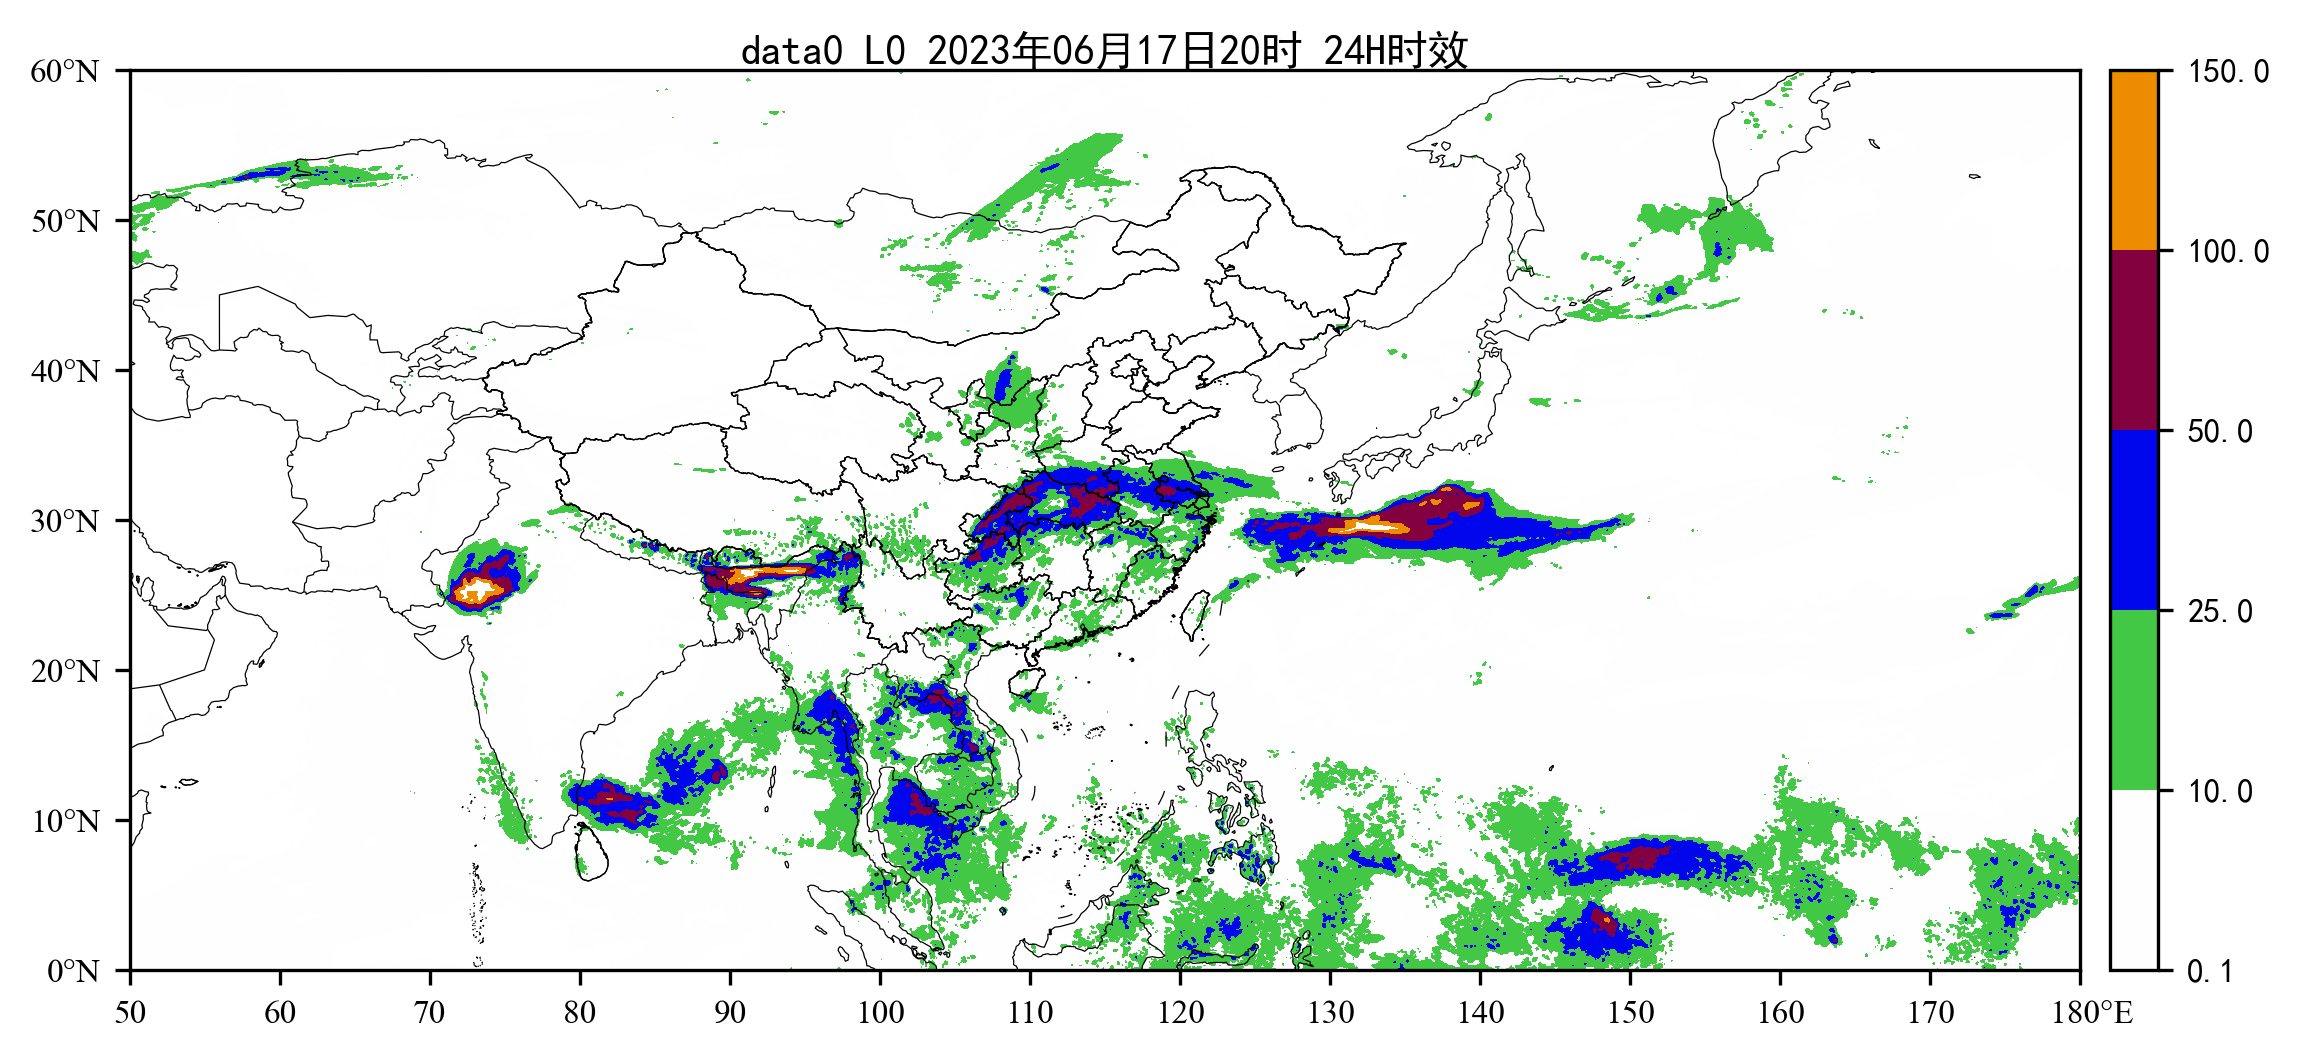

In [33]:
from nimm.base.cube_base import read_meteva_griddata_from_cube
## 等经纬度cube 转为meteva_base网格数据
grd0 = read_meteva_griddata_from_cube(cube0)
meb.tool.plot_tools.contourf_2d_grid(grd0, clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)

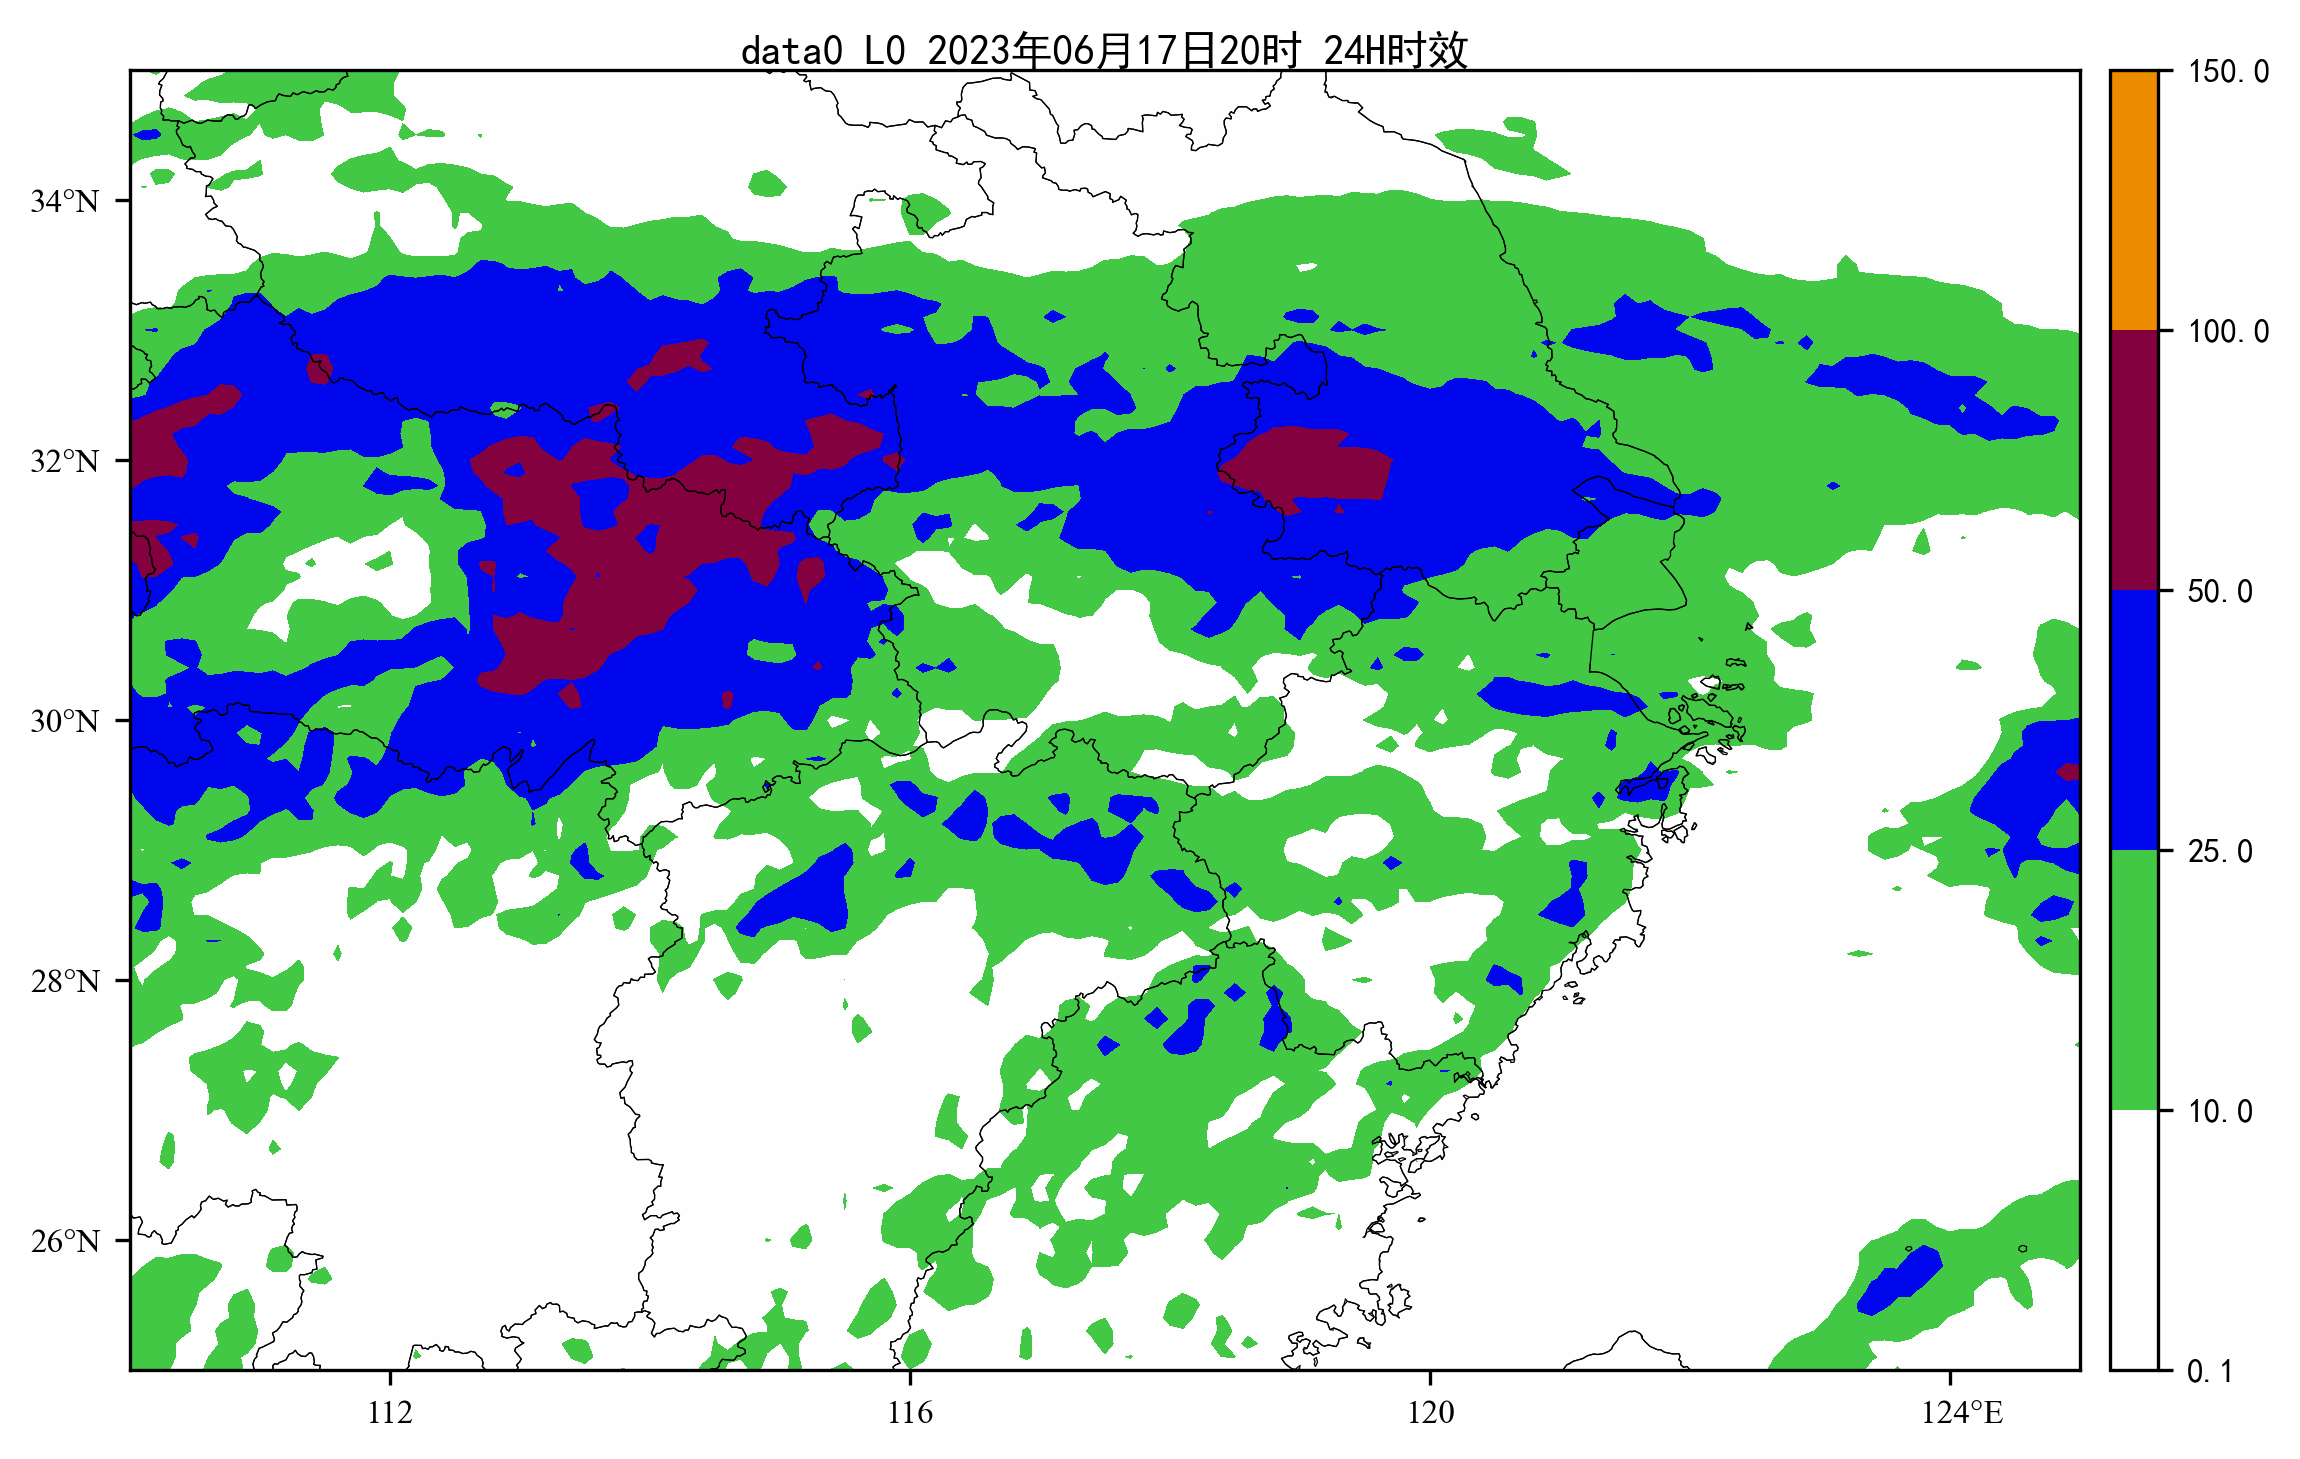

In [34]:
## 等经纬度cube 转为meteva_base网格数据, 带输出网格信息范围(meb.grid类)
to_grid_info = meb.grid([110,125,0.1],[25,35,0.1])
grd1 = read_meteva_griddata_from_cube(cube0, grid_info=to_grid_info)
meb.tool.plot_tools.contourf_2d_grid(grd1, clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)

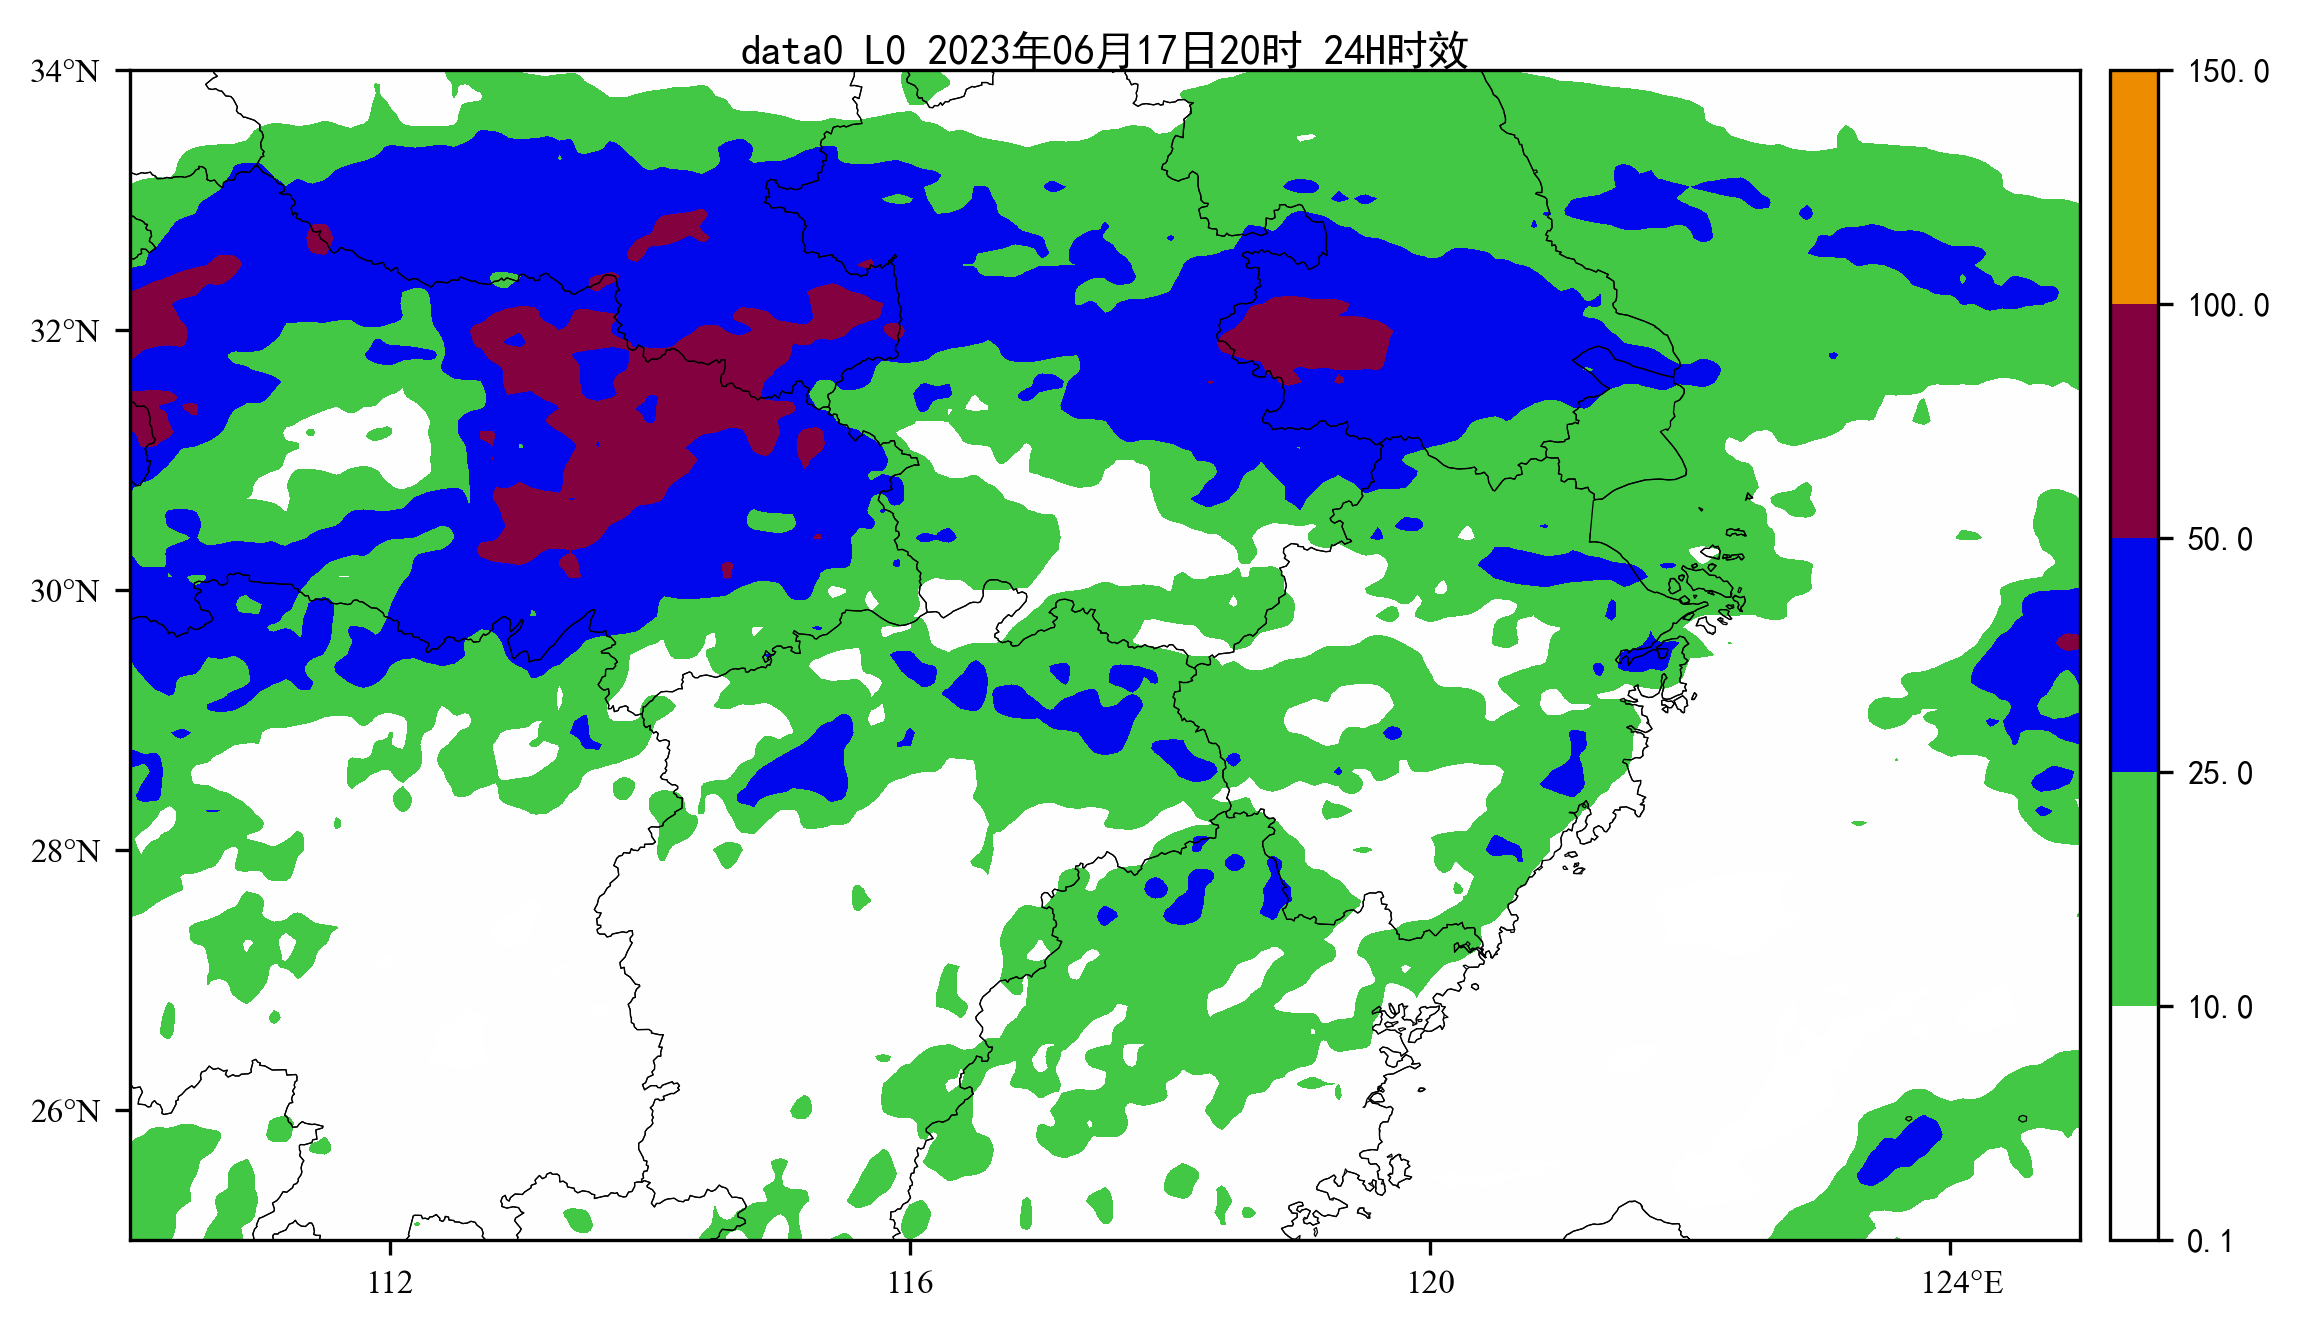

In [37]:
## 等经纬度cube 转为meteva_base网格数据, 带输出网格信息范围(字典dict模式)
to_grid_dict  = { 'dlon':0.03, 'dlat':0.03, #数据xy间隔
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':501,'nlat':301,
                }#等经纬度网格，距离单位°
spatial_grid = 'latlon'
grd2 = read_meteva_griddata_from_cube(cube0, grid_info=to_grid_dict)
meb.tool.plot_tools.contourf_2d_grid(grd2, clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)

equalarea
latlon
{'dlon': 0.03, 'dlat': 0.03, 'slon': 110, 'slat': 25, 'nlon': 501, 'nlat': 301, 'spatial_grid': 'latlon'}


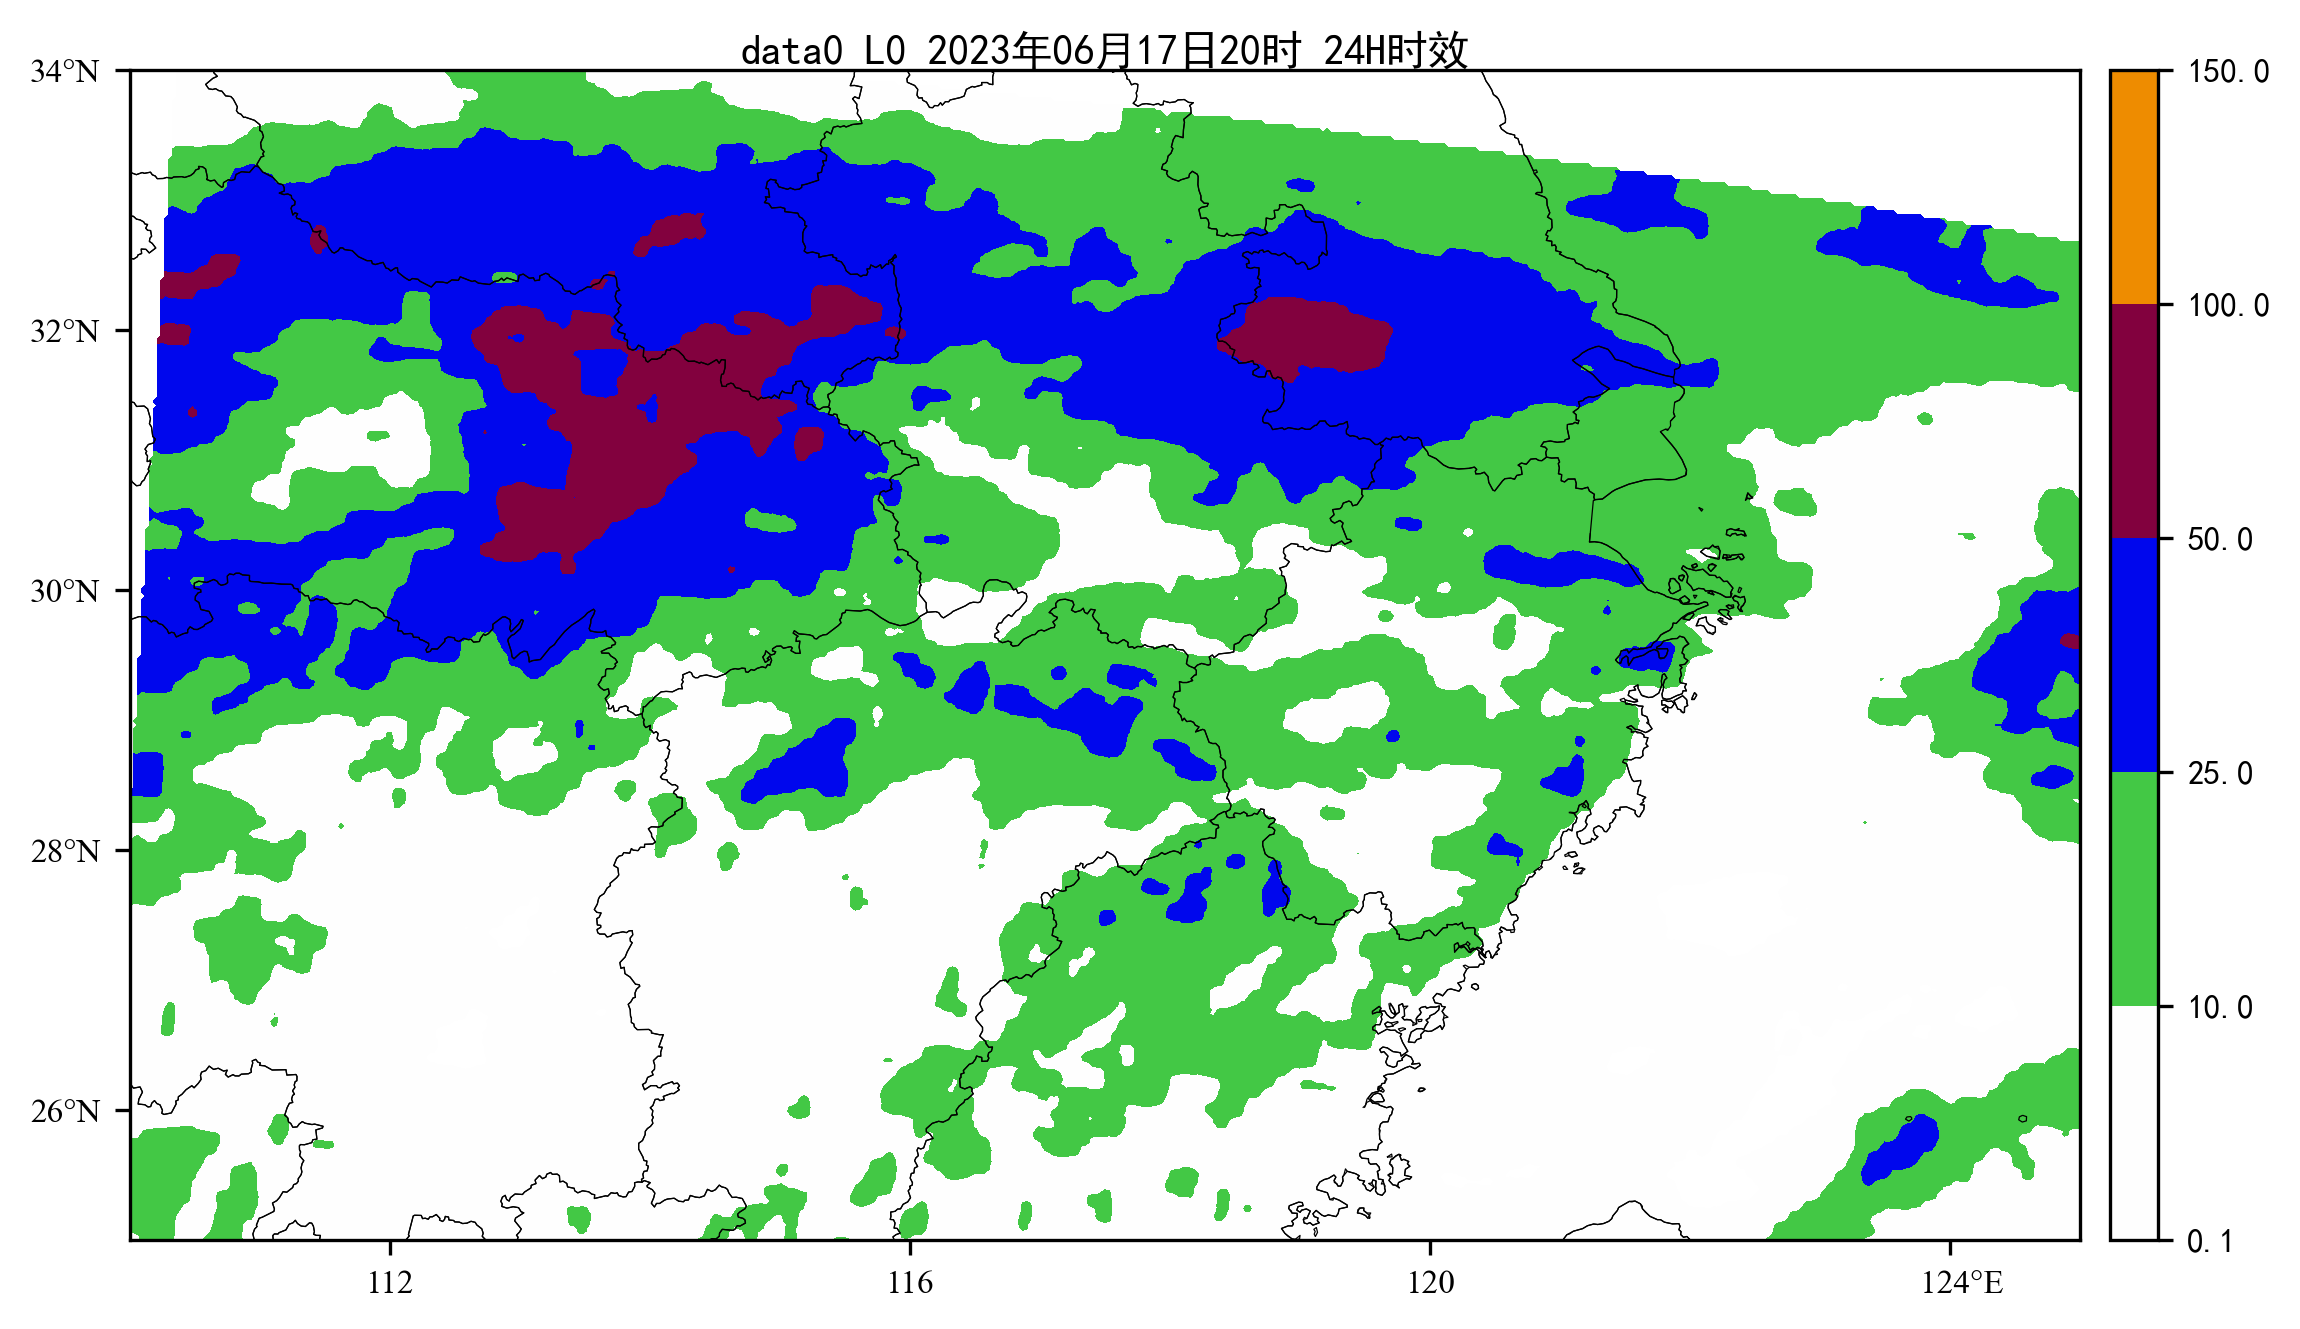

In [45]:
## 等距cube 转为meteva_base网格数据, 带输出网格信息范围(字典dict模式)
from_cube_dict = { 'dlon':10000, 'dlat':10000, #数据xy间隔，m
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':151,'nlat':101,
                }#等距网格，距离单位m，转换到的网格信息

to_grid_dict  = { 'dlon':0.03, 'dlat':0.03, #数据xy间隔
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':501,'nlat':301,
                }#等经纬度网格，距离单位°
spatial_grid = 'equalarea'
grd3 = read_meteva_griddata_from_cube(cube3, spatial_grid=spatial_grid, 
                                      cube_info=from_cube_dict, grid_info=to_grid_dict)
meb.tool.plot_tools.contourf_2d_grid(grd3, clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)

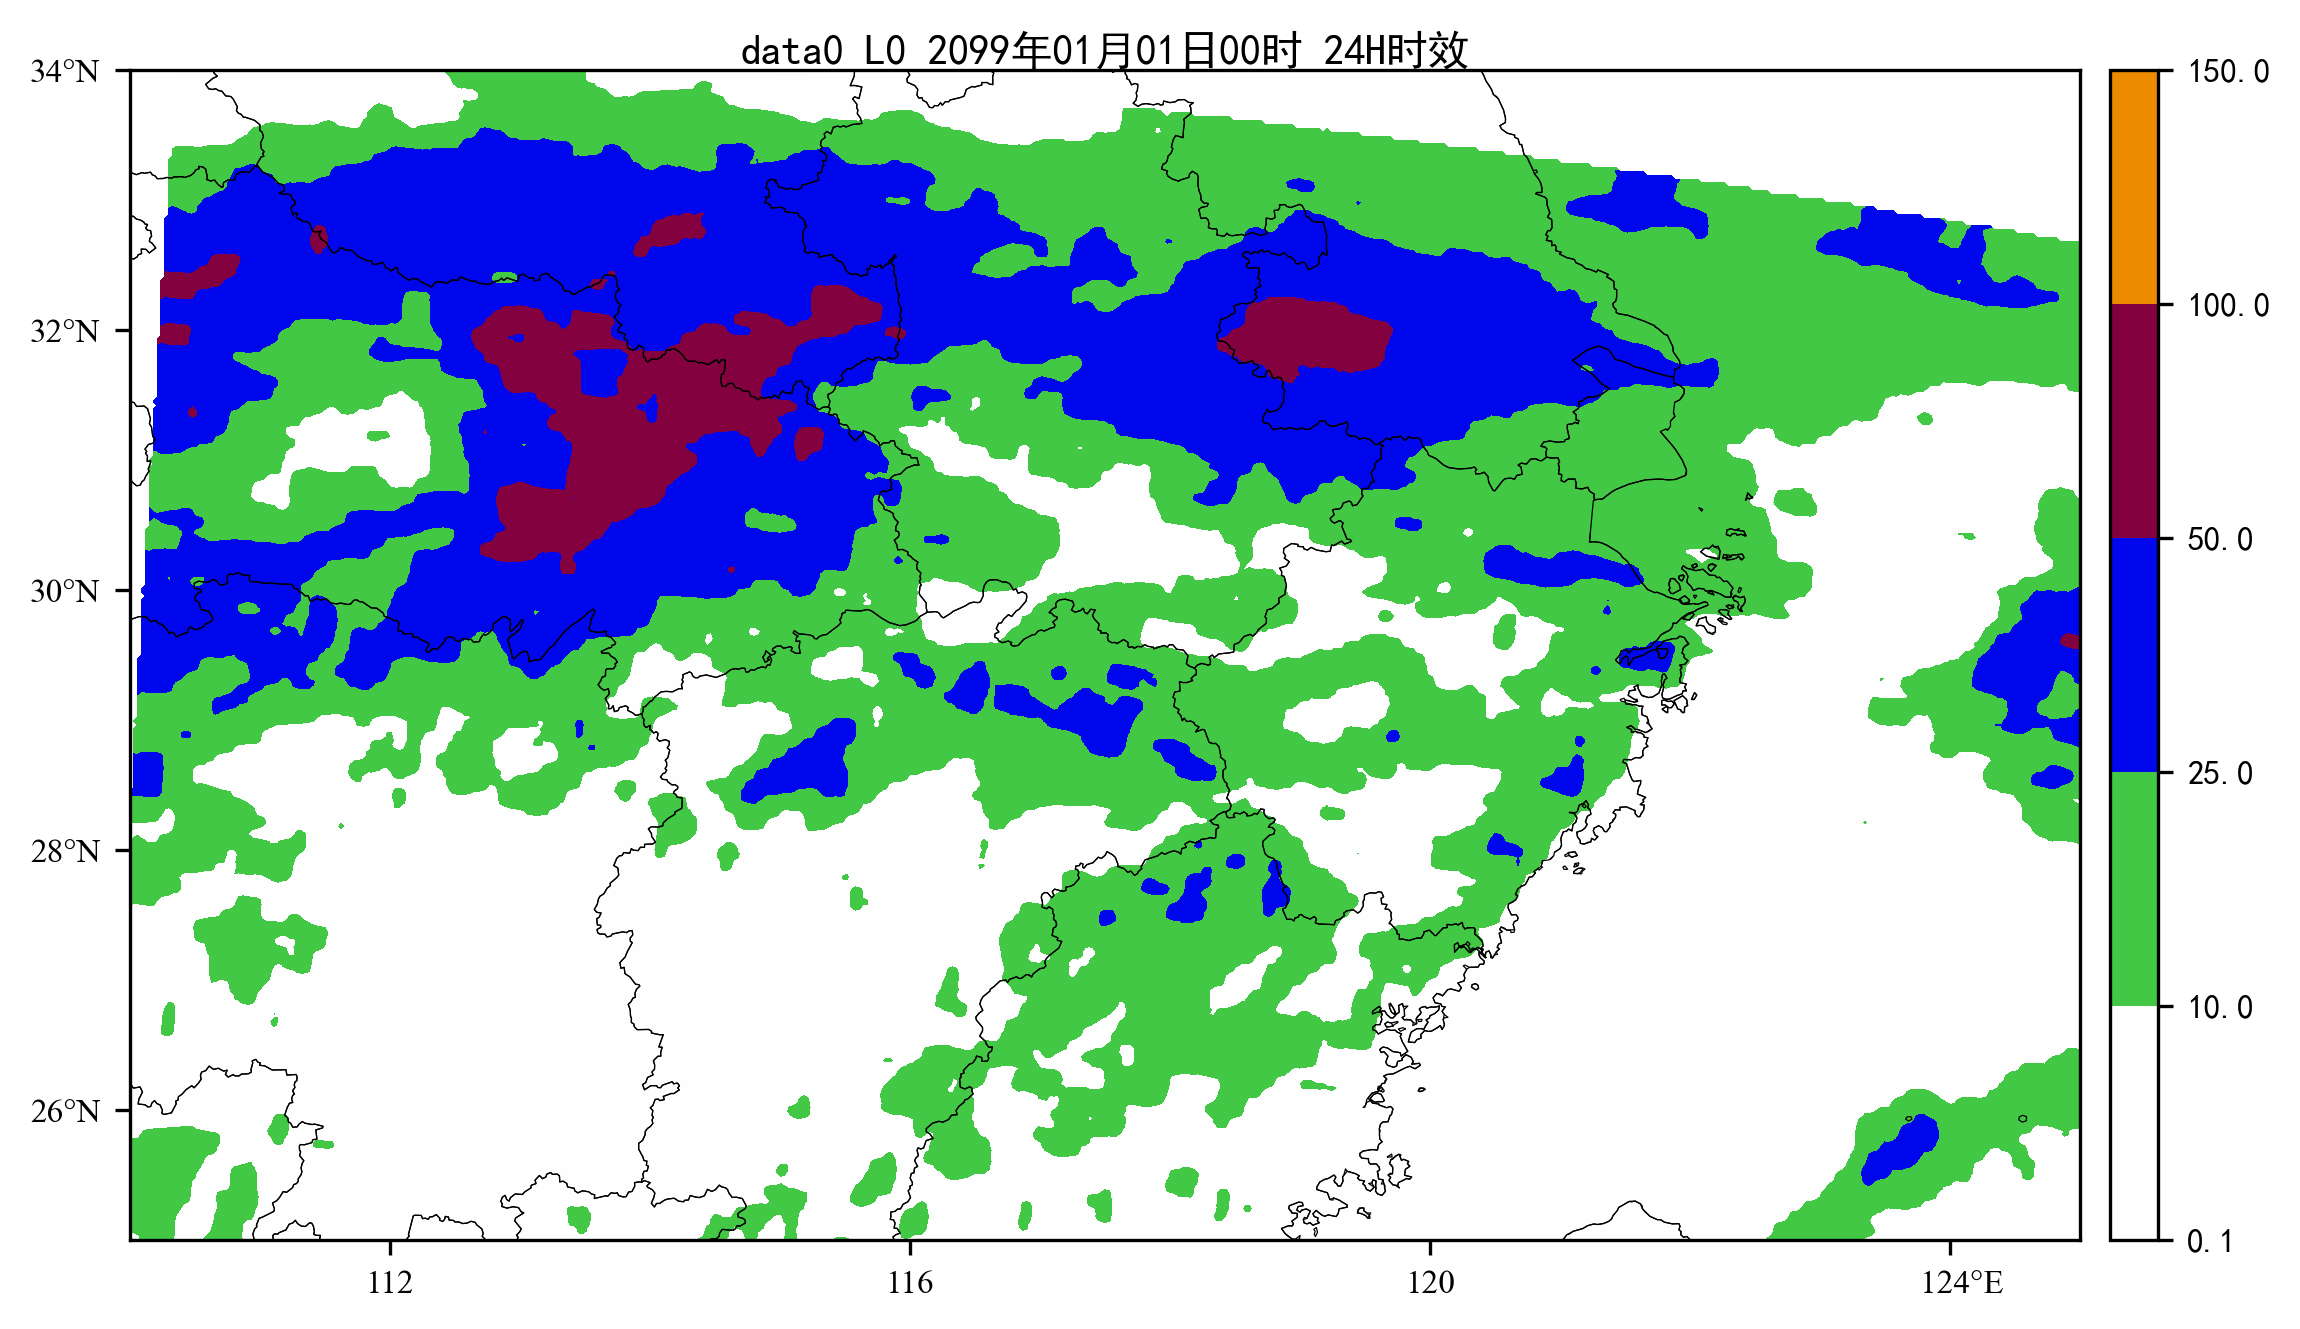

In [54]:
## 等距cube 转为meteva_base网格数据, 带输出网格信息范围(字典dict模式)
from_cube_dict = { 'dlon':10000, 'dlat':10000, #数据xy间隔，m
                'slon':110, 'slat':25, #起始点经纬度定位
                'nlon':151,'nlat':101,
                }#等距网格，距离单位m，转换到的网格信息

to_grid_dict  = meb.grid(glon=[110, 125, 0.03], glat=[25,34,0.03])
spatial_grid = 'equalarea'

grd3 = read_meteva_griddata_from_cube(cube3, spatial_grid=spatial_grid, 
                                      cube_info=from_cube_dict, grid_info=to_grid_dict)
meb.tool.plot_tools.contourf_2d_grid(grd3, clevs=[0.1,10,25,50,100,150], cmap=meb.cmaps.rain_24h)